In [ ]:
# Exercice 2 : Réseau de neurones sur Iris
# Objectif : classifier les fleurs Iris en 3classes avec un MLP simple

In [2]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


In [4]:
!pip install networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 12.8 MB/s  0:00:00


In [6]:
print("Appareils disponibles :", tf.config.list_physical_devices())

Appareils disponibles : [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


E0000 00:00:1791791491.980339  643797 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [5]:
# Etape 1 : Importer les librairies
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Fixer la graine aléatoire pour la reproductibilité
tf.keras.utils.set_random_seed(42)

I0000 00:00:1791791424.914423  643797 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791791425.275089  643797 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791791426.786515  643797 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [21]:
# Étape 2 : Charger le dataset Iris

# 1. Chargement du jeu de données Iris depuis la bibliothèque scikit-learn.
# 'iris' est un objet de type dictionnaire (ou Bunch) qui contient toutes les données et métadonnées.
iris = load_iris()

# 2. Extraction des caractéristiques (features) : X est une matrice (tableau 2D).
# Elle contient 150 lignes (les échantillons de fleurs) et 4 colonnes (les variables mesurées : 
# longueur et largeur des sépales et des pétales).
X = iris.data  # 4 features

# 3. Extraction des étiquettes (targets) : y est un vecteur (tableau 1D) de 150 éléments.
# Chaque valeur correspond à la classe de la fleur (0 pour Setosa, 1 pour Versicolor, 2 pour Virginica).
y = iris.target  # classes 0, 1, 2

# 4. Affichage des dimensions de la matrice X pour vérifier qu'on a bien 150 lignes et 4 colonnes.
print("Dimensions X :", X.shape)

# 5. Affichage des dimensions du vecteur y pour vérifier qu'on a bien 150 étiquettes correspondantes.
print("Dimensions y :", y.shape)

Dimensions X : (150, 4)
Dimensions y : (150,)


In [8]:
# Étape 3 : Visualiser les 5 premières lignes

# 1. Afficher les 5 premiers échantillons de la matrice X (les caractéristiques d'entrée).
# 'X[:5]' prend les 5 premières lignes et toutes les colonnes (les 4 mesures de chaque fleur : 
# longueur/largeur des sépales et pétales).
print("Exemples de X :\n", X[:5])

# 2. Afficher les 5 premières étiquettes du vecteur y (les classes cibles).
# 'y[:5]' prend les 5 premières valeurs correspondantes, qui s'affichent sous forme de zéros 
# (ce qui signifie que les 5 premières fleurs du dataset appartiennent toutes à la classe 0 : Iris Setosa).
print("Exemples de y :\n", y[:5])

Exemples de X :
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
Exemples de y :
 [0 0 0 0 0]


In [10]:
# Étape 4 : Split train/test
# On sépare avant tout calcul de statistiques. L'option stratify=y garde les 3 classes à égalité dans les deux jeux.

# 1. Utilisation de train_test_split pour découper les données en deux parties : 
# l'apprentissage (train) et l'évaluation finale (test).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,       # Réserve 20 % des données pour le test (les 80 % restants serviront à entraîner le modèle).
    stratify=y,          # Indispensable ici : garantit que les proportions des 3 classes d'iris sont respectées équitablement dans le train et le test.
    random_state=42      # Fixe le générateur aléatoire pour s'assurer que le mélange des données est identique à chaque lancement (reproductibilité).
)

# 2. Affichage de la forme du jeu d'entraînement (120 lignes pour l'apprentissage, 4 caractéristiques).
print("Taille train :", X_train.shape)

# 3. Affichage de la forme du jeu de test (30 lignes pour évaluer le modèle sans qu'il ne les ait jamais vues).
print("Taille test :", X_test.shape)

Taille train : (120, 4)
Taille test : (30, 4)


In [11]:
# Étape 5 : One-Hot Encoding pour les sorties

# 1. Initialisation de l'encodeur OneHotEncoder. 
# 'sparse_output=False' demande de retourner un tableau NumPy classique (dense) 
# plutôt qu'une matrice creuse (sparse matrix), ce qui est plus simple à manipuler avec TensorFlow.
encoder = OneHotEncoder(sparse_output=False)

# 2. Transformation des étiquettes d'entraînement (y_train).
# 'y_train.reshape(-1, 1)' transforme le tableau 1D (ex: [0, 1, 2...]) en un tableau 2D d'une seule colonne, 
# car scikit-learn attend obligatoirement du 2D en entrée.
# 'fit_transform' apprend les catégories uniques présentes dans y_train et les convertit en vecteurs binaires 
# (ex: la classe 0 devient [1., 0., 0.], la classe 1 devient [0., 1., 0.], etc.).
y_train = encoder.fit_transform(y_train.reshape(-1, 1))  # y en 2D

# 3. Transformation des étiquettes de test (y_test).
# On utilise uniquement 'transform' (et non 'fit_transform') pour que l'encodeur utilise 
# exactement les mêmes classes et le même ordre qu'il vient d'apprendre sur le train.
y_test = encoder.transform(y_test.reshape(-1, 1))

# 4. Affichage des 5 premières lignes des sorties encodées pour vérifier le format 
# (on doit voir des lignes composées de 1 et de 0).
print("Sorties encodées :\n", y_train[:5])

Sorties encodées :
 [[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]


In [12]:
# Étape 6 : Normaliser les features (standardisation)
# Le scaler est ajusté sur le train uniquement ; le test est seulement transformé.

# 1. Initialisation du StandardScaler de scikit-learn.
# Il va centrer les données (moyenne = 0) et les réduire (écart-type = 1) 
# pour que toutes les variables pèsent de la même manière dans l'apprentissage du réseau.
scaler = StandardScaler()

# 2. Ajustement (fit) sur le jeu d'entraînement ET transformation (transform).
# Le scaler calcule la moyenne et l'écart-type uniquement sur X_train, puis applique la formule.
# C'est capital pour éviter la fuite de données (data leakage) en provenance du test set.
X_train = scaler.fit_transform(X_train)

# 3. Transformation simple du jeu de test.
# On utilise uniquement 'transform' (et non 'fit') pour appliquer exactement 
# la même moyenne et le même écart-type calculés sur le train, sans tricher avec le test.
X_test = scaler.transform(X_test)

# 4. Affichage des 5 premières lignes des caractéristiques normalisées 
# (on observe des valeurs centrées autour de 0, positives et négatives).
print("Features normalisées :\n", X_train[:5])

Features normalisées :
 [[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

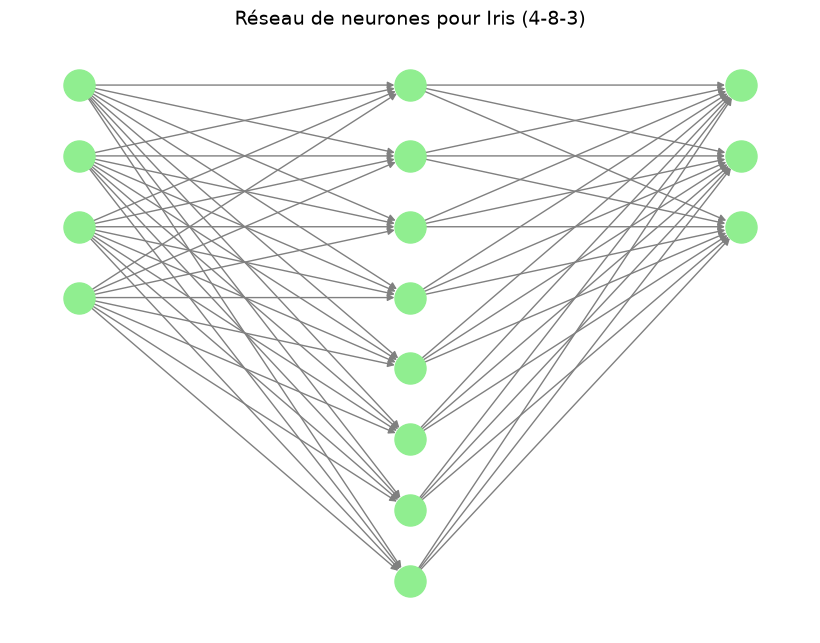

In [22]:
# Étape 7 : Construire le modèle MLP

# 1. Création d'un modèle séquentiel (les couches s'empilent les unes après les autres de manière linéaire).
model = Sequential([
    # Couche d'entrée (Input) : indique que le modèle reçoit des vecteurs de 4 caractéristiques (les 4 mesures de la fleur).
    Input(shape=(4,)),
    
    # Couche cachée (Hidden Layer) : composée de 8 neurones avec la fonction d'activation ReLU 
    # (Rectified Linear Unit), qui permet d'introduire de la non-linéarité dans le modèle.
    Dense(8, activation='relu'),
    
    # Couche de sortie (Output Layer) : composée de 3 neurones (un pour chaque classe d'iris) 
    # avec la fonction d'activation 'softmax', qui transforme les scores bruts en probabilités dont la somme vaut 1.
    Dense(3, activation='softmax')
])

# 2. Affichage d'un tableau récapitulatif de l'architecture du réseau, du nombre de couches 
# et du nombre de paramètres (poids et biais) à entraîner.
model.summary()

# Visualisation graphique du réseau de neurones (architecture 4-8-3)

# Définition de la liste représentant le nombre de neurones par couche : 
# 4 en entrée, 8 dans la couche cachée, et 3 en sortie.
layers = [4, 8, 3]

# Création d'un graphe orienté vide avec NetworkX pour y stocker nos nœuds (neurones) et arêtes (connexions).
G = nx.DiGraph()
pos = {}            # Dictionnaire pour stocker les coordonnées (x, y) de chaque neurone
layer_positions = [] # Liste pour mémoriser les identifiants des neurones par couche

# Boucle pour créer chaque neurone et lui attribuer une position en colonnes
for l, n_neurons in enumerate(layers):
    layer_pos = []
    for i in range(n_neurons):
        node_id = f"L{l}N{i}" # Identifiant unique du neurone (ex: "L0N0" pour le 1er neurone de la couche 0)
        G.add_node(node_id, layer=l)
        pos[node_id] = (l, -i)  # Positionne les neurones en colonnes (l = abscisse, -i = ordonnée pour l'alignement vertical)
        layer_pos.append(node_id)
    layer_positions.append(layer_pos)

# Boucle pour connecter chaque neurone d'une couche 'l' à tous les neurones de la couche suivante 'l+1' (fully connected / Dense)
for l in range(len(layers)-1):
    for src in layer_positions[l]:
        for dst in layer_positions[l+1]:
            G.add_edge(src, dst)

# Paramétrage et affichage du dessin du réseau avec Matplotlib
plt.figure(figsize=(8, 6))
nx.draw(G, pos, with_labels=False,
        node_size=500, node_color="lightgreen", edge_color="gray")
plt.title("Réseau de neurones pour Iris (4-8-3)", fontsize=14)
plt.show()

In [16]:
# Étape 8 : Compiler le modèle
model.compile(
    # 1. L'optimiseur 'adam' : c'est l'algorithme d'optimisation (inspiré de la descente de gradient) 
    # qui va mettre à jour automatiquement les poids du réseau pour minimiser l'erreur au fil des entraînements.
    optimizer='adam',
    
    # 2. La fonction de perte (loss) 'categorical_crossentropy' : elle mesure l'écart entre 
    # les probabilités prédites par le modèle et les vraies étiquettes encodées en One-Hot (parfait pour la classification multi-classes).
    loss='categorical_crossentropy',
    
    # 3. La métrique 'accuracy' (précision) : utilisée pour suivre et afficher le pourcentage 
    # de bonnes prédictions faites par le modèle pendant et après l'entraînement.
    metrics=['accuracy']
)

In [17]:
# Étape 9 : Entraîner le modèle

# La méthode 'fit' lance l'apprentissage proprement dit du réseau de neurones.
# Elle retourne un objet 'history' qui stocke l'évolution de la perte (loss) et de la précision (accuracy) à chaque époque.
history = model.fit(
    X_train,             # 1. Les caractéristiques d'entrée normalisées (les 120 échantillons d'entraînement).
    y_train,             # 2. Les étiquettes cibles encodées en One-Hot (les réponses exactes attendues par le réseau).
    epochs=100,          # 3. Le nombre d'époques : le modèle va parcourir et analyser l'intégralité du jeu d'entraînement 100 fois de suite.
    batch_size=5,        # 4. La taille des lots (batch) : le réseau met à jour ses poids tous les 5 échantillons (au lieu d'attendre la fin de tout le dataset).
    validation_split=0.1 # 5. Met de côté 10 % des données d'entraînement pour tester le modèle à la fin de chaque époque sans qu'il n'apprenne dessus.
)

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6389 - loss: 0.8449 - val_accuracy: 0.6667 - val_loss: 0.8814
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7222 - loss: 0.7955 - val_accuracy: 0.6667 - val_loss: 0.8358
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7037 - loss: 0.7498 - val_accuracy: 0.6667 - val_loss: 0.7926
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7222 - loss: 0.7077 - val_accuracy: 0.6667 - val_loss: 0.7534
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7407 - loss: 0.6687 - val_accuracy: 0.6667 - val_loss: 0.7191
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7685 - loss: 0.6339 - val_accuracy: 0.6667 - val_loss: 0.6890
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7778 - loss: 0.6033 - val_accuracy: 0.6667 - val_loss: 0.6631
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7778 - loss: 0.5764 - val_accuracy: 0.6667 - v

In [ ]:
"""
Explication des paramètres :
X_train / y_train : Les données d'entraînement (les caractéristiques d'entrées normalisées et les étiquettes encodées en One-Hot).

epochs=100 : Le nombre de cycles d'apprentissage complets sur l'ensemble du jeu de données d'entraînement.
Le réseau va voir 100 fois toutes ses données pour ajuster ses poids progressivement.

batch_size=5 : Le nombre d'échantillons traités par le réseau avant de mettre à jour les poids.
Ici, le modèle fait des mises à jour par petits paquets de 5 exemples, ce qui stabilise l'apprentissage par rapport 
à une mise à jour échantillon par échantillon (Stochastic Gradient Descent pur) ou tout d'un coup (Batch Gradient Descent).

validation_split=0.1 : Met de côté 10 % des données d'entraînement (tirées du jeu X_train/y_train)
pour évaluer les performances du modèle à la fin de chaque époque sans qu'il ne les utilise pour apprendre, 
ce qui permet de surveiller l'apparition éventuelle d'un surapprentissage (overfitting).

"""


In [18]:
# Étape 10 : Évaluer le modèle sur le test set

# 1. Utilisation de la méthode 'evaluate' pour tester le modèle sur des données qu'il n'a jamais vues (X_test et y_test).
# Cette méthode retourne deux valeurs : la perte finale (loss) et la métrique de performance (accuracy).
loss, accuracy = model.evaluate(X_test, y_test)

# 2. Affichage formaté de la précision en pourcentage avec deux chiffres après la virgule.
# 'accuracy * 100' convertit la valeur (ex: 0.9333) en pourcentage (93.33%).
print(f"Test Accuracy: {accuracy*100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.9333 - loss: 0.1620
Test Accuracy: 93.33%


In [19]:
# Étape 11 : Visualiser la prédiction pour quelques exemples

# 1. Obtenir les prédictions du modèle sur l'ensemble du jeu de test (X_test).
# La méthode 'predict' renvoie pour chaque fleur un tableau de 3 probabilités 
# (correspondant aux 3 classes de l'iris, issues de la couche softmax).
predictions = model.predict(X_test)

# 2. Afficher les prédictions brutes pour les 5 premiers exemples, arrondies à 3 décimales 
# (ex: [0.998, 0.002, 0.0.] signifie que le modèle est sûr à 99.8% que c'est la classe 0).
print("Prédictions :\n", predictions[:5].round(3))

# 3. Transformer les probabilités en classes concrètes (0, 1 ou 2) pour les 20 premiers exemples.
# 'np.argmax(..., axis=1)' cherche l'indice de la valeur la plus élevée dans chaque vecteur de probabilités.
print("Classes prédites :", np.argmax(predictions, axis=1)[:20])

# 4. Faire la même conversion (argmax) sur les vraies étiquettes de test encodées en One-Hot (y_test) 
# pour retrouver la vraie classe d'origine (0, 1 ou 2) et pouvoir comparer facilement[cite: 8].
print("Vraies classes : ", np.argmax(y_test, axis=1)[:20])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
Prédictions :
 [[0.998 0.002 0.   ]
 [0.001 0.206 0.793]
 [0.043 0.948 0.009]
 [0.016 0.978 0.007]
 [0.999 0.001 0.   ]]
Classes prédites : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2]
Vraies classes :  [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2]


In [20]:
# Analyse finale et création du tableau comparatif

# 1. Convertir les vecteurs One-Hot (ex: [1., 0., 0.]) en indices de classes (ex: 0) 
# pour les vraies étiquettes du jeu de test. 'axis=1' cherche l'indice de la valeur maximale.
y_true = np.argmax(y_test, axis=1)

# 2. Faire exactement la même conversion pour les probabilités de prédiction sorties par le modèle 
# afin d'obtenir la classe finale choisie par le réseau (0, 1 ou 2).
y_pred = np.argmax(predictions, axis=1)

# 3. Créer un DataFrame pandas en remettant les caractéristiques (X_test) dans leur échelle d'origine 
# (grâce à inverse_transform) pour que les valeurs en centimètres redeviennent lisibles, 
# en reprenant les vrais noms de colonnes du dataset et en arrondissant à 1 décimale.
df = pd.DataFrame(
    scaler.inverse_transform(X_test), columns=iris.feature_names
).round(1)

# 4. Ajouter une nouvelle colonne 'True_Class' au DataFrame contenant les vraies espèces réelles.
df["True_Class"] = y_true

# 5. Ajouter une nouvelle colonne 'Predicted_Class' contenant les espèces prédites par le modèle.
df["Predicted_Class"] = y_pred

# 6. Afficher les 10 premières lignes du tableau pour comparer facilement et visuellement 
# les mesures physiques des fleurs, la vraie classe et celle trouvée par l'intelligence artificielle.
df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),True_Class,Predicted_Class
0,4.4,3.0,1.3,0.2,0,0
1,6.1,3.0,4.9,1.8,2,2
2,4.9,2.4,3.3,1.0,1,1
3,5.0,2.3,3.3,1.0,1,1
4,4.4,3.2,1.3,0.2,0,0
5,6.3,3.3,4.7,1.6,1,1
6,4.6,3.6,1.0,0.2,0,0
7,5.4,3.4,1.7,0.2,0,0
8,6.5,3.0,5.2,2.0,2,2
9,5.4,3.0,4.5,1.5,1,1
